In [1]:
import os, gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import torch
import torch.nn as nn

In [2]:
np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("PyTorch:", torch.__version__)

print("TF GPUs:", tf.config.list_physical_devices("GPU"))
print("Torch CUDA available:", torch.cuda.is_available())


TensorFlow: 2.21.0
Keras: 3.13.2
PyTorch: 2.11.0+cpu
TF GPUs: []
Torch CUDA available: False


In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch version: 2.11.0+cpu
CUDA available: False


In [4]:
DATA_DIR = "datasets/fashion-mnist"
BASE_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
         "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    path = os.path.join(DATA_DIR, f)
    if not os.path.exists(path):
        print("downloading", f)
        urllib.request.urlretrieve(BASE_URL + f, path)

def read_idx(fname, is_image):
    with gzip.open(os.path.join(DATA_DIR, fname)) as fh:
        buf = np.frombuffer(fh.read(), dtype=np.uint8, offset=16 if is_image else 8)
    return buf.reshape(-1, 28, 28) if is_image else buf

x_train = read_idx(FILES[0], True);  y_train = read_idx(FILES[1], False)
x_test  = read_idx(FILES[2], True);  y_test  = read_idx(FILES[3], False)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

# pandas: class balance
pd.Series(y_train).map(dict(enumerate(class_names))).value_counts().to_frame("images")

downloading train-images-idx3-ubyte.gz
downloading train-labels-idx1-ubyte.gz
downloading t10k-images-idx3-ubyte.gz
downloading t10k-labels-idx1-ubyte.gz
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


,images
Ankle boot,6000
T-shirt/top,6000
Dress,6000
Pullover,6000
Sneaker,6000
Sandal,6000
Trouser,6000
Shirt,6000
Coat,6000
Bag,6000


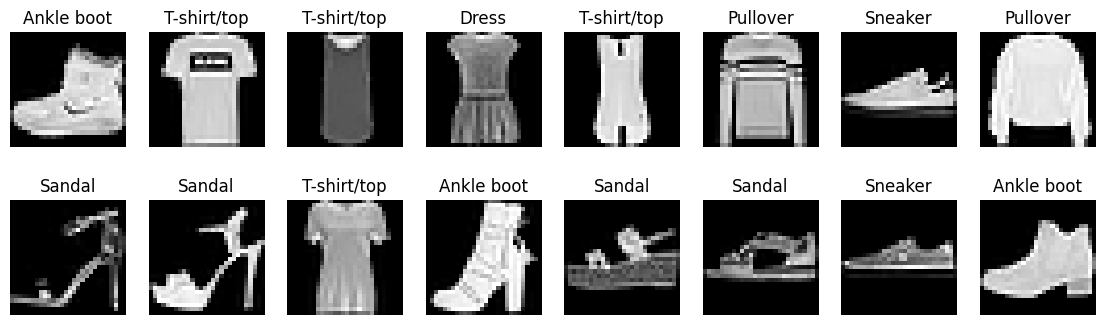

In [5]:
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(ax.flat, range(16)):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(class_names[y_train[i]])
    ax.axis("off")
plt.show()

In [6]:
# Flatten and scale; use 10,000 samples so it trains in seconds
Xtr = x_train[:10000].reshape(10000, -1) / 255.0
ytr = y_train[:10000]
Xte = x_test.reshape(len(x_test), -1) / 255.0

mlp = MLPClassifier(hidden_layer_sizes=(128,), max_iter=20, random_state=42)
mlp.fit(Xtr, ytr)
print("MLP test accuracy:", accuracy_score(y_test, mlp.predict(Xte)))

MLP test accuracy: 0.8465


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP accuracy on shifted images: 0.2535


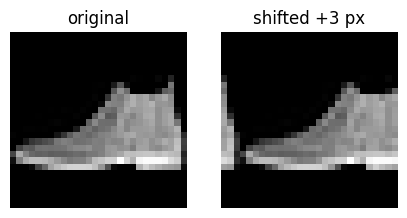

In [7]:
# Shift every test image 3 pixels to the right
x_test_shifted = np.roll(x_test, shift=3, axis=2)
Xte_shifted = x_test_shifted.reshape(len(x_test), -1) / 255.0
acc_shift = accuracy_score(y_test, mlp.predict(Xte_shifted))
print("MLP accuracy on shifted images:", acc_shift)

fig, ax = plt.subplots(1, 2, figsize=(5, 3))
ax[0].imshow(x_test[0], cmap="gray"); ax[0].set_title("original"); ax[0].axis("off")
ax[1].imshow(x_test_shifted[0], cmap="gray"); ax[1].set_title("shifted +3 px"); ax[1].axis("off")
plt.show()
